In [ ]:
from sklearn.svm import SVC
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from pprint import pprint
import time

In [ ]:
# BỘ DỮ LIỆU THỨ NHẤT  596 MẪU

from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()   # mau: 569;   features: 30;    label: 2
x,y = data.data, data.target

In [ ]:
print(x.shape)
print(y.shape)

(569, 30)
(569,)


In [ ]:
model = SVC(probability=True)
pprint("Bộ tham số mặc định của mô hình")
pprint(model.get_params())

'Bộ tham số mặc định của mô hình'
{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': True,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}


In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Model_svc(x,y):
  bd = time.time()
  model = SklearnSVC(probability=True)
  loss = -cross_val_score(
        model, x, y, cv=5, scoring='neg_log_loss'
    ).mean()
  acc = cross_val_score(
        model, x, y, cv=5, scoring='accuracy'
    ).mean()
  kt = time.time()
  tgchay = kt - bd
  print(f"Accuracy    : {acc:.4f}")
  print(f"Log Loss    : {loss:.4f}")
  print(f"Thời gian   : {tgchay:.4f} giây")
  return loss, acc,  tgchay

In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Grid_Search_SVC(x, y):
    bd = time.time()
    model = SklearnSVC(probability=True)
    param_grid = {
        "C": [0.01, 0.1, 0.5, 1, 5, 10, 50, 100, 500, 1000],
        "gamma": [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1]
    }
    grid = GridSearchCV(
        model,
        param_grid,
        cv=5,
        scoring={'loss': 'neg_log_loss', 'acc': 'accuracy'},
        refit='loss',
        n_jobs=-1
    )
    grid.fit(x, y)
    loss = -grid.best_score_
    acc = grid.cv_results_['mean_test_acc'][grid.best_index_]
    print(f"Best Params: {grid.best_params_}")
    print(f"Best Accuracy: {acc:.4f}")
    kt = time.time()
    tgchay = kt - bd
    return loss, acc, tgchay

In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Random_Search_SVC(x, y):
    bd = time.time()
    model = SklearnSVC(probability=True)
    param_dist = {
        "C": np.logspace(-2, 2, 50),
        "gamma": np.logspace(-4, 1, 50)
    }
    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=100,
        cv=5,
        scoring={'loss': 'neg_log_loss', 'acc': 'accuracy'},
        refit='loss',
        random_state=42,
        n_jobs=-1
    )
    random_search.fit(x, y)
    loss = -random_search.best_score_
    acc = random_search.cv_results_['mean_test_acc'][random_search.best_index_]
    print("\nBest Random Search Parameters:")
    print(random_search.best_params_)
    kt = time.time()
    tgchay = kt - bd
    return loss, acc, tgchay

In [ ]:
from sklearn.svm import SVC as SklearnSVC
from sklearn.model_selection import cross_validate
import numpy as np
import time

def PSO_SVC(x, y):
    bd = time.time()

    def evaluate_model(params):
        C = 10 ** params[0]
        gamma = 10 ** params[1]
        model = SklearnSVC(C=C, gamma=gamma, probability=True)
        scores = cross_validate(
            model, x, y, cv=5, scoring=['neg_log_loss', 'accuracy'], n_jobs=-1
        )
        loss = -scores['test_neg_log_loss'].mean()
        acc = scores['test_accuracy'].mean()
        return loss, acc

    def fitness(params):
        loss, _ = evaluate_model(params)
        return loss

    n_particles = 30
    n_iter = 20
    dim = 2
    bounds = [(-2, 3), (-4, 1)]

    positions = np.random.uniform(
        [b[0] for b in bounds], [b[1] for b in bounds], (n_particles, dim)
    )
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    gbest = pbest[np.argmin(pbest_scores)]

    # BỔ SUNG 1: Khởi tạo mảng trống để lưu lịch sử Loss tối ưu qua từng vòng lặp
    gbest_loss_history = []

    w = 0.7
    c1 = 1.5
    c2 = 1.5

    print("--- Bắt đầu tối ưu hóa bầy đàn (PSO) ---")
    for t in range(n_iter):
        r1 = np.random.rand(n_particles, dim)
        r2 = np.random.rand(n_particles, dim)

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions += velocities

        for d, (lo, hi) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], lo, hi)

        scores = np.array([fitness(p) for p in positions])

        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        gbest = pbest[np.argmin(pbest_scores)]
        gbest_score = np.min(pbest_scores)

        # BỔ SUNG 2: Nhét điểm số của vòng lặp 't' vào mảng lịch sử
        gbest_loss_history.append(gbest_score)

        print(f"Vòng lặp thứ {t+1:02d} | Best Loss = {gbest_score:.6f}")

    kt = time.time()
    tgchay = kt - bd

    best_C = 10 ** gbest[0]
    best_gamma = 10 ** gbest[1]
    final_loss, final_acc = evaluate_model(gbest)

    print("\n" + "="*40)
    print("       KẾT QUẢ TỐI ƯU HÓA PSO       ")
    print("="*40)
    print(f"Tham số tối ưu : C = {best_C:.4f} | gamma = {best_gamma:.6f}")
    print(f"Best Accuracy  : {final_acc:.4f} ({final_acc*100:.2f}%)")
    print(f"Best Log Loss  : {final_loss:.4f}")
    print(f"Thời gian chạy : {tgchay:.4f} giây")
    print("="*40)

    # BỔ SUNG 3: Trả về bộ 4 tham số (mảng lịch sử nằm ở cuối)
    return final_loss, final_acc, tgchay, gbest_loss_history

In [ ]:
import numpy as np
import time
from sklearn.svm import SVC as SklearnSVC
from sklearn.model_selection import cross_validate


def AIW_PSO_SVC(x, y,
                n_particles=30,
                n_iter=20,
                w_min=0.4, w_max=0.9,
                c1_start=2.5, c1_end=0.5,
                c2_start=0.5, c2_end=2.5,
                stagnation_limit=3,
                reinit_ratio=0.2,
                seed=42):
    """
    PSO cải tiến cho SVM: Adaptive Inertia Weight (AIW) + TVAC + Stagnation-based partial reinit.
    Giữ nguyên fitness/bounds/cách đánh giá như PSO_SVC gốc để so sánh công bằng.
    """
    rng = np.random.default_rng(seed)
    start = time.time()

    def evaluate_model(params):
        C = 10 ** params[0]
        gamma = 10 ** params[1]
        model = SklearnSVC(C=C, gamma=gamma, probability=True)
        scores = cross_validate(
            model, x, y, cv=5, scoring=['neg_log_loss', 'accuracy'], n_jobs=-1
        )
        loss = -scores['test_neg_log_loss'].mean()
        acc = scores['test_accuracy'].mean()
        return loss, acc

    def fitness(params):
        loss, _ = evaluate_model(params)
        return loss

    dim = 2
    bounds = [(-2, 3), (-4, 1)]
    lo = np.array([b[0] for b in bounds])
    hi = np.array([b[1] for b in bounds])

    positions = rng.uniform(lo, hi, (n_particles, dim))
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    gbest = pbest[np.argmin(pbest_scores)].copy()
    gbest_score = np.min(pbest_scores)

    gbest_score_history = [gbest_score]
    w_history = []
    stagnation_counter = 0
    EPS = 1e-10

    print("--- Bắt đầu tối ưu hóa bầy đàn (AIW-PSO) ---")
    for t in range(n_iter):
        # ---- TVAC: c1 giảm dần, c2 tăng dần theo vòng lặp ----
        c1 = c1_start - (c1_start - c1_end) * (t / n_iter)
        c2 = c2_start + (c2_end - c2_start) * (t / n_iter)

        # ---- AIW: w riêng cho từng particle theo fitness hiện tại ----
        f_min = pbest_scores.min()
        f_avg = pbest_scores.mean()
        if f_avg - f_min > EPS:
            w_vec = w_min + (w_max - w_min) * (pbest_scores - f_min) / (f_avg - f_min)
            w_vec = np.clip(w_vec, w_min, w_max)
        else:
            w_vec = np.full(n_particles, w_max)
        w_history.append(w_vec.mean())
        w_col = w_vec[:, None]

        r1, r2 = rng.random((n_particles, dim)), rng.random((n_particles, dim))
        velocities = (w_col * velocities
                      + c1 * r1 * (pbest - positions)
                      + c2 * r2 * (gbest - positions))
        positions += velocities

        for d, (bl, bh) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], bl, bh)

        scores = np.array([fitness(p) for p in positions])
        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        new_gbest_score = pbest_scores.min()
        if gbest_score - new_gbest_score > EPS:
            gbest_score = new_gbest_score
            gbest = pbest[np.argmin(pbest_scores)].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # ---- Stagnation detection: reinit một phần particle tệ nhất ----
        if stagnation_counter >= stagnation_limit:
            n_reinit = max(1, int(reinit_ratio * n_particles))
            worst_idx = np.argsort(pbest_scores)[-n_reinit:]
            positions[worst_idx] = rng.uniform(lo, hi, (n_reinit, dim))
            velocities[worst_idx] = 0
            stagnation_counter = 0

        gbest_score_history.append(gbest_score)
        print(f'Vòng lặp thứ {t+1:02d} | Best Loss = {gbest_score:.6f} '
              f'| w_avg:{w_vec.mean():.3f} c1:{c1:.2f} c2:{c2:.2f}')

    end = time.time()
    tgchay = end - start

    best_C = 10 ** gbest[0]
    best_gamma = 10 ** gbest[1]
    final_loss, final_acc = evaluate_model(gbest)

    print("\n" + "="*40)
    print("     KẾT QUẢ TỐI ƯU HÓA AIW-PSO      ")
    print("="*40)
    print(f"Tham số tối ưu : C = {best_C:.4f} | gamma = {best_gamma:.6f}")
    print(f"Best Accuracy  : {final_acc:.4f} ({final_acc*100:.2f}%)")
    print(f"Best Log Loss  : {final_loss:.4f}")
    print(f"Thời gian chạy : {tgchay:.4f} giây")
    print("="*40)

    return final_loss, final_acc, tgchay, gbest_score_history, w_history

In [ ]:
Model_svc(x,y)

Accuracy    : 0.9122
Log Loss    : 0.2034
Thời gian   : 0.2499 giây


(np.float64(0.20336144922070748),
 np.float64(0.9121720229777983),
 0.24991965293884277)

In [ ]:
Grid_Search_SVC(x,y)

Best Params: {'C': 10, 'gamma': 0.0001}
Best Accuracy: 0.9314


(np.float64(0.17041052276107066),
 np.float64(0.9314392175128086),
 43.73229146003723)

In [ ]:
Random_Search_SVC(x,y)


Best Random Search Parameters:
{'gamma': np.float64(0.00015998587196060574), 'C': np.float64(15.264179671752318)}


(np.float64(0.1844935555990219),
 np.float64(0.9402111473373699),
 45.674590826034546)

In [ ]:
PSO_SVC(x,y)

--- Bắt đầu tối ưu hóa bầy đàn (PSO) ---
Vòng lặp thứ 01 | Best Loss = 0.170220
Vòng lặp thứ 02 | Best Loss = 0.170220
Vòng lặp thứ 03 | Best Loss = 0.169908
Vòng lặp thứ 04 | Best Loss = 0.169663
Vòng lặp thứ 05 | Best Loss = 0.169663
Vòng lặp thứ 06 | Best Loss = 0.169663
Vòng lặp thứ 07 | Best Loss = 0.169663
Vòng lặp thứ 08 | Best Loss = 0.169494
Vòng lặp thứ 09 | Best Loss = 0.169494
Vòng lặp thứ 10 | Best Loss = 0.169494
Vòng lặp thứ 11 | Best Loss = 0.169217
Vòng lặp thứ 12 | Best Loss = 0.169217
Vòng lặp thứ 13 | Best Loss = 0.169217
Vòng lặp thứ 14 | Best Loss = 0.169217
Vòng lặp thứ 15 | Best Loss = 0.169217
Vòng lặp thứ 16 | Best Loss = 0.169217
Vòng lặp thứ 17 | Best Loss = 0.169217
Vòng lặp thứ 18 | Best Loss = 0.169217
Vòng lặp thứ 19 | Best Loss = 0.169053
Vòng lặp thứ 20 | Best Loss = 0.169053

       KẾT QUẢ TỐI ƯU HÓA PSO       
Tham số tối ưu : C = 9.2407 | gamma = 0.000100
Best Accuracy  : 0.9367 (93.67%)
Best Log Loss  : 0.1703
Thời gian chạy : 115.8932 giây


(np.float64(0.17029311041726528),
 np.float64(0.9367179009470579),
 115.89318227767944,
 [np.float64(0.17021967069877064),
  np.float64(0.17021967069877064),
  np.float64(0.16990831595493971),
  np.float64(0.16966267860904966),
  np.float64(0.16966267860904966),
  np.float64(0.16966267860904966),
  np.float64(0.16966267860904966),
  np.float64(0.16949395240854553),
  np.float64(0.16949395240854553),
  np.float64(0.16949395240854553),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16921708170279537),
  np.float64(0.16905280203071088),
  np.float64(0.16905280203071088)])

In [ ]:
AIW_PSO_SVC(x,y)

--- Bắt đầu tối ưu hóa bầy đàn (AIW-PSO) ---
Vòng lặp thứ 01 | Best Loss = 0.180806 | w_avg:0.752 c1:2.50 c2:0.50
Vòng lặp thứ 02 | Best Loss = 0.179315 | w_avg:0.720 c1:2.40 c2:0.60
Vòng lặp thứ 03 | Best Loss = 0.170562 | w_avg:0.632 c1:2.30 c2:0.70
Vòng lặp thứ 04 | Best Loss = 0.170562 | w_avg:0.588 c1:2.20 c2:0.80
Vòng lặp thứ 05 | Best Loss = 0.168608 | w_avg:0.573 c1:2.10 c2:0.90
Vòng lặp thứ 06 | Best Loss = 0.168608 | w_avg:0.647 c1:2.00 c2:1.00
Vòng lặp thứ 07 | Best Loss = 0.168608 | w_avg:0.765 c1:1.90 c2:1.10
Vòng lặp thứ 08 | Best Loss = 0.168608 | w_avg:0.748 c1:1.80 c2:1.20
Vòng lặp thứ 09 | Best Loss = 0.168608 | w_avg:0.737 c1:1.70 c2:1.30
Vòng lặp thứ 10 | Best Loss = 0.168401 | w_avg:0.724 c1:1.60 c2:1.40
Vòng lặp thứ 11 | Best Loss = 0.168401 | w_avg:0.718 c1:1.50 c2:1.50
Vòng lặp thứ 12 | Best Loss = 0.168401 | w_avg:0.738 c1:1.40 c2:1.60
Vòng lặp thứ 13 | Best Loss = 0.168401 | w_avg:0.745 c1:1.30 c2:1.70
Vòng lặp thứ 14 | Best Loss = 0.168401 | w_avg:0.756 c1:1.

(np.float64(0.17052134927878732),
 np.float64(0.934979040521658),
 101.51560854911804,
 [np.float64(0.18205259012069885),
  np.float64(0.18080584485158022),
  np.float64(0.17931526994098562),
  np.float64(0.17056239033665577),
  np.float64(0.17056239033665577),
  np.float64(0.16860790844122012),
  np.float64(0.16860790844122012),
  np.float64(0.16860790844122012),
  np.float64(0.16860790844122012),
  np.float64(0.16860790844122012),
  np.float64(0.16840138396100937),
  np.float64(0.16840138396100937),
  np.float64(0.16840138396100937),
  np.float64(0.16840138396100937),
  np.float64(0.16840138396100937),
  np.float64(0.16807756151403225),
  np.float64(0.16807756151403225),
  np.float64(0.16807756151403225),
  np.float64(0.16807756151403225),
  np.float64(0.16807756151403225),
  np.float64(0.16807756151403225)],
 [np.float64(0.752323499646488),
  np.float64(0.7201153729961776),
  np.float64(0.631951110946289),
  np.float64(0.5881139556799594),
  np.float64(0.572648347729985),
  np.float

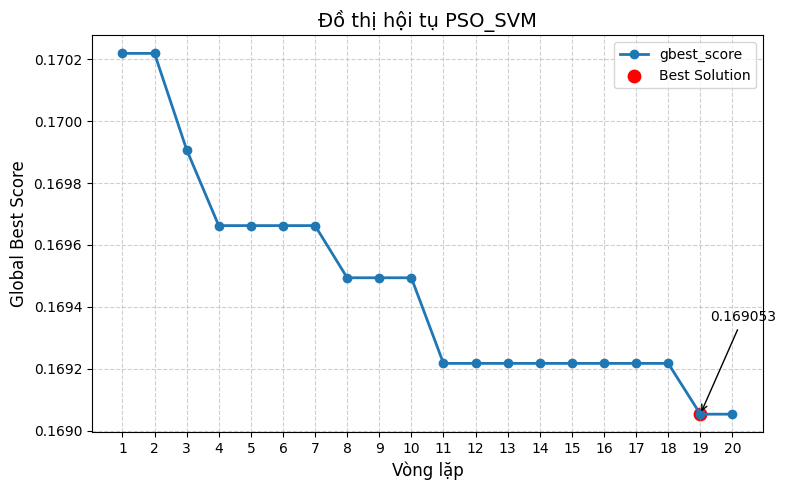

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.17021967069877064,
  0.17021967069877064,
  0.16990831595493971,
  0.16966267860904966,
  0.16966267860904966,
  0.16966267860904966,
  0.16966267860904966,
  0.16949395240854553,
  0.16949395240854553,
  0.16949395240854553,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16921708170279537,
  0.16905280203071088,
  0.16905280203071088
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ PSO_SVM", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

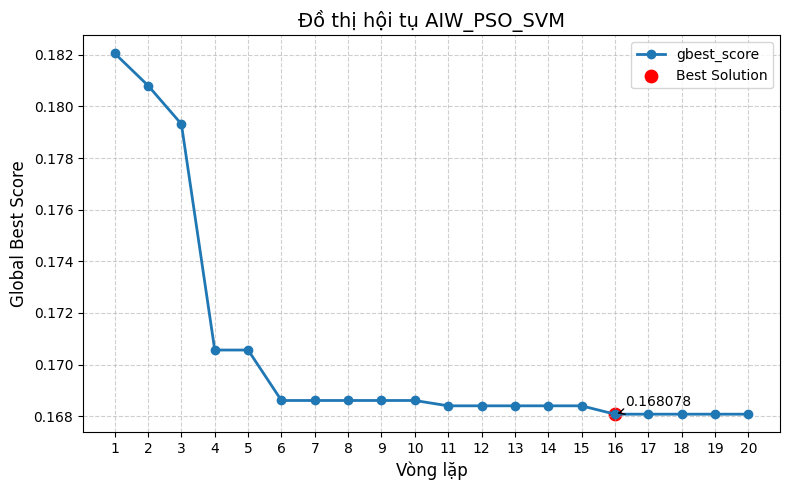

In [1]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.18205259012069885,
  0.18080584485158022,
  0.17931526994098562,
  0.17056239033665577,
  0.17056239033665577,
  0.16860790844122012,
  0.16860790844122012,
  0.16860790844122012,
  0.16860790844122012,
  0.16860790844122012,
  0.16840138396100937,
  0.16840138396100937,
  0.16840138396100937,
  0.16840138396100937,
  0.16840138396100937,
  0.16807756151403225,
  0.16807756151403225,
  0.16807756151403225,
  0.16807756151403225,
  0.16807756151403225
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ AIW_PSO_SVM", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# BỘ DỮ LIỆU THỨ HAI 2000 MẪU

from sklearn.datasets import fetch_openml
# from sklearn.preprocessing import LabelEncoder, StandardScaler
# from sklearn.impute import SimpleImputer
# import numpy as np
# print("Đang tải dữ liệu từ OpenML...")
# x1, y1 = fetch_openml(
#     "letter",
#     version=1,
#     return_X_y=True,
#     as_frame=False
# )
# imputer = SimpleImputer(strategy='mean')
# x1 = imputer.fit_transform(x1)
# scaler = StandardScaler()
# x1 = scaler.fit_transform(x1)
# if y1.dtype.kind in ['O', 'U']:
#     le = LabelEncoder()
#     y1 = le.fit_transform(y1)
x1, y1 = fetch_openml(
    "letter",
    version=1,
    return_X_y=True,
    as_frame=False
)

print(f"Kích thước tập X: {x1.shape}")
print(f"Kích thước tập Y: {y1.shape}")

Kích thước tập X: (20000, 16)
Kích thước tập Y: (20000,)


In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Model_svc(x1,y1):
  bd = time.time()
  model = SklearnSVC(probability=True)
  loss = -cross_val_score(
        model, x1, y1, cv=3, scoring='neg_log_loss'
    ).mean()
  acc = cross_val_score(
        model, x1, y1, cv=3, scoring='accuracy'
    ).mean()
  kt = time.time()
  tgchay = kt - bd
  return loss, acc, tgchay

In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Grid_Search_SVC(x1, y1):
    bd = time.time()
    model = SklearnSVC(probability=True, cache_size=1024)
    param_grid = {
        "C": [0.1, 1, 10],
        "gamma": [0.001, 0.01]
    }
    grid = GridSearchCV(
        model,
        param_grid,
        cv=3,
        scoring={'loss': 'neg_log_loss', 'acc': 'accuracy'},
        refit='loss',
        n_jobs=-1
    )
    grid.fit(x1, y1)
    loss = -grid.best_score_
    acc = grid.cv_results_['mean_test_acc'][grid.best_index_]
    print(f"Best Params: {grid.best_params_}")
    print(f"Best Accuracy: {acc:.4f}")
    kt = time.time()
    tgchay = kt - bd
    return loss, acc, tgchay


In [ ]:
from sklearn.svm import SVC as SklearnSVC

def Random_Search_SVC(x1, y1):
    bd = time.time()
    model = SklearnSVC(probability=True, cache_size=1024)
    param_dist = {
        "C": np.logspace(-1, 2, 20),
        "gamma": np.logspace(-3, 0, 20)
    }
    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=20,
        cv=3,
        scoring={'loss': 'neg_log_loss', 'acc': 'accuracy'},
        refit='loss',
        random_state=42,
        n_jobs=-1
    )
    random_search.fit(x1, y1)
    loss = -random_search.best_score_
    acc = random_search.cv_results_['mean_test_acc'][random_search.best_index_]
    print("\nBest Random Search Parameters:")
    print(random_search.best_params_)
    kt = time.time()
    tgchay = kt - bd
    return loss, acc, tgchay

In [ ]:
from sklearn.svm import SVC as SklearnSVC
from sklearn.model_selection import cross_validate
import numpy as np
import time

def PSO_SVC(x1, y1):
    bd = time.time()

    def evaluate_model(params):
        C = 10 ** params[0]
        gamma = 10 ** params[1]
        model = SklearnSVC(C=C, gamma=gamma, probability=True, cache_size=1024)
        scores = cross_validate(
            model, x1, y1, cv=3, scoring=['neg_log_loss', 'accuracy'], n_jobs=-1
        )
        loss = -scores['test_neg_log_loss'].mean()
        acc = scores['test_accuracy'].mean()
        return loss, acc

    def fitness(params):
        loss, _ = evaluate_model(params)
        return loss

    n_particles = 10
    n_iter = 20
    dim = 2
    bounds = [(-2, 3), (-4, 1)]

    positions = np.random.uniform(
        [b[0] for b in bounds], [b[1] for b in bounds], (n_particles, dim)
    )
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    gbest = pbest[np.argmin(pbest_scores)]

    # BỔ SUNG 1: Khởi tạo mảng trống để lưu lịch sử Loss tối ưu qua từng vòng lặp
    gbest_loss_history = []

    w = 0.7
    c1 = 1.5
    c2 = 1.5

    print("--- Bắt đầu tối ưu hóa bầy đàn (PSO) ---")
    for t in range(n_iter):
        r1 = np.random.rand(n_particles, dim)
        r2 = np.random.rand(n_particles, dim)

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions += velocities

        for d, (lo, hi) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], lo, hi)

        scores = np.array([fitness(p) for p in positions])

        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        gbest = pbest[np.argmin(pbest_scores)]
        gbest_score = np.min(pbest_scores)

        # BỔ SUNG 2: Nhét điểm số của vòng lặp 't' vào mảng lịch sử
        gbest_loss_history.append(gbest_score)

        print(f"Vòng lặp thứ {t+1:02d} | Best Loss = {gbest_score:.6f}")

    kt = time.time()
    tgchay = kt - bd

    best_C = 10 ** gbest[0]
    best_gamma = 10 ** gbest[1]
    final_loss, final_acc = evaluate_model(gbest)

    print("\n" + "="*40)
    print("       KẾT QUẢ TỐI ƯU HÓA PSO       ")
    print("="*40)
    print(f"Tham số tối ưu : C = {best_C:.4f} | gamma = {best_gamma:.6f}")
    print(f"Best Accuracy  : {final_acc:.4f} ({final_acc*100:.2f}%)")
    print(f"Best Log Loss  : {final_loss:.4f}")
    print(f"Thời gian chạy : {tgchay:.4f} giây")
    print("="*40)

    # BỔ SUNG 3: Trả về bộ 4 tham số (mảng lịch sử nằm ở cuối)
    return final_loss, final_acc, tgchay, gbest_loss_history

In [ ]:
from sklearn.svm import SVC as SklearnSVC
from sklearn.model_selection import cross_validate
import numpy as np
import time


def AIW_PSO_SVC(
    x1, y1,
    n_particles=10,
    n_iter=20,
    w_min=0.4,
    w_max=0.9,
    c1_start=2.5,
    c1_end=0.5,
    c2_start=0.5,
    c2_end=2.5,
    stagnation_limit=3,
    reinit_ratio=0.2,
    seed=42
):
    """
    AIW-PSO cho bộ dữ liệu thứ hai.

    Giữ nguyên điều kiện của PSO_SVC gốc:
    - C = 10**params[0], gamma = 10**params[1]
    - bounds = [(-2, 3), (-4, 1)]
    - fitness = 3-fold CV Log Loss
    - n_particles = 10, n_iter = 20
    - SVC(probability=True, cache_size=1024)
    """
    rng = np.random.default_rng(seed)
    bd = time.time()

    def evaluate_model(params):
        C = 10 ** params[0]
        gamma = 10 ** params[1]

        model = SklearnSVC(
            C=C,
            gamma=gamma,
            probability=True,
            cache_size=1024
        )

        scores = cross_validate(
            model,
            x1,
            y1,
            cv=3,
            scoring=["neg_log_loss", "accuracy"],
            n_jobs=-1
        )

        loss = -scores["test_neg_log_loss"].mean()
        acc = scores["test_accuracy"].mean()
        return loss, acc

    def fitness(params):
        loss, _ = evaluate_model(params)
        return loss

    dim = 2
    bounds = [(-2, 3), (-4, 1)]

    lo = np.array([b[0] for b in bounds])
    hi = np.array([b[1] for b in bounds])

    positions = rng.uniform(lo, hi, (n_particles, dim))
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    gbest = pbest[np.argmin(pbest_scores)].copy()
    gbest_score = np.min(pbest_scores)

    gbest_score_history = [gbest_score]
    w_history = []

    stagnation_counter = 0
    EPS = 1e-10

    print("--- Bắt đầu tối ưu hóa bầy đàn (AIW-PSO) ---")

    for t in range(n_iter):
        # TVAC: c1 giảm, c2 tăng theo iteration
        c1 = c1_start - (c1_start - c1_end) * (t / n_iter)
        c2 = c2_start + (c2_end - c2_start) * (t / n_iter)

        # AIW: particle tốt ưu tiên khai thác, particle kém ưu tiên khám phá
        f_min = pbest_scores.min()
        f_avg = pbest_scores.mean()

        if f_avg - f_min > EPS:
            w_vec = (
                w_min
                + (w_max - w_min)
                * (pbest_scores - f_min)
                / (f_avg - f_min)
            )
            w_vec = np.clip(w_vec, w_min, w_max)
        else:
            w_vec = np.full(n_particles, w_max)

        w_history.append(w_vec.mean())

        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))

        velocities = (
            w_vec[:, None] * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )

        positions += velocities

        for d, (bl, bh) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], bl, bh)

        scores = np.array([fitness(p) for p in positions])

        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        new_gbest_score = pbest_scores.min()

        if gbest_score - new_gbest_score > EPS:
            gbest_score = new_gbest_score
            gbest = pbest[np.argmin(pbest_scores)].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # Nếu bị trì trệ: khởi tạo lại 20% particle có pbest tệ nhất
        if stagnation_counter >= stagnation_limit:
            n_reinit = max(1, int(reinit_ratio * n_particles))
            worst_idx = np.argsort(pbest_scores)[-n_reinit:]

            positions[worst_idx] = rng.uniform(
                lo, hi, (n_reinit, dim)
            )
            velocities[worst_idx] = 0

            stagnation_counter = 0

        gbest_score_history.append(gbest_score)

        print(
            f"Vòng lặp thứ {t + 1:02d} | "
            f"Best Loss = {gbest_score:.6f} | "
            f"w_avg = {w_vec.mean():.3f} | "
            f"c1 = {c1:.2f} | c2 = {c2:.2f}"
        )

    kt = time.time()
    tgchay = kt - bd

    best_C = 10 ** gbest[0]
    best_gamma = 10 ** gbest[1]
    final_loss, final_acc = evaluate_model(gbest)

    print("\n" + "=" * 40)
    print("     KẾT QUẢ TỐI ƯU HÓA AIW-PSO     ")
    print("=" * 40)
    print(f"Tham số tối ưu : C = {best_C:.4f} | gamma = {best_gamma:.6f}")
    print(f"Best Accuracy  : {final_acc:.4f} ({final_acc * 100:.2f}%)")
    print(f"Best Log Loss  : {final_loss:.4f}")
    print(f"Thời gian chạy : {tgchay:.4f} giây")
    print("=" * 40)

    return (
        final_loss,
        final_acc,
        tgchay,
        gbest_score_history,
        w_history
    )

In [ ]:
Model_svc(x1,y1)

(np.float64(0.2656104304016544),
 np.float64(0.919300142103606),
 140.93283247947693)

In [ ]:
Grid_Search_SVC(x1,y1)

Best Params: {'C': 10, 'gamma': 0.01}
Best Accuracy: 0.9653


(np.float64(0.12911092161829044),
 np.float64(0.9653000473288667),
 704.8809823989868)

In [ ]:
Random_Search_SVC(x1,y1)


Best Random Search Parameters:
{'gamma': np.float64(0.0379269019073225), 'C': np.float64(3.79269019073225)}


(np.float64(0.10352882518522306),
 np.float64(0.974000069873494),
 3268.9196705818176)

In [ ]:
PSO_SVC(x1,y1)

--- Bắt đầu tối ưu hóa bầy đàn (PSO) ---
Vòng lặp thứ 01 | Best Loss = 0.103955
Vòng lặp thứ 02 | Best Loss = 0.103751
Vòng lặp thứ 03 | Best Loss = 0.103391
Vòng lặp thứ 04 | Best Loss = 0.103391
Vòng lặp thứ 05 | Best Loss = 0.103391
Vòng lặp thứ 06 | Best Loss = 0.103219
Vòng lặp thứ 07 | Best Loss = 0.103219
Vòng lặp thứ 08 | Best Loss = 0.103219
Vòng lặp thứ 09 | Best Loss = 0.103219
Vòng lặp thứ 10 | Best Loss = 0.103219
Vòng lặp thứ 11 | Best Loss = 0.103219
Vòng lặp thứ 12 | Best Loss = 0.103177
Vòng lặp thứ 13 | Best Loss = 0.102995
Vòng lặp thứ 14 | Best Loss = 0.102995
Vòng lặp thứ 15 | Best Loss = 0.102995
Vòng lặp thứ 16 | Best Loss = 0.102869
Vòng lặp thứ 17 | Best Loss = 0.102869
Vòng lặp thứ 18 | Best Loss = 0.102869
Vòng lặp thứ 19 | Best Loss = 0.102677
Vòng lặp thứ 20 | Best Loss = 0.102677

       KẾT QUẢ TỐI ƯU HÓA PSO       
Tham số tối ưu : C = 4.2772 | gamma = 0.035829
Best Accuracy  : 0.9741 (97.41%)
Best Log Loss  : 0.1030
Thời gian chạy : 26960.6267 giây


(np.float64(0.10298408832565105),
 np.float64(0.9741000498729938),
 26960.62668800354,
 [np.float64(0.10395454745920994),
  np.float64(0.10375098420673139),
  np.float64(0.1033914514099785),
  np.float64(0.1033914514099785),
  np.float64(0.1033914514099785),
  np.float64(0.1032187522344145),
  np.float64(0.1032187522344145),
  np.float64(0.1032187522344145),
  np.float64(0.1032187522344145),
  np.float64(0.1032187522344145),
  np.float64(0.1032187522344145),
  np.float64(0.10317738411797367),
  np.float64(0.10299515149923834),
  np.float64(0.10299515149923834),
  np.float64(0.10299515149923834),
  np.float64(0.10286923293390317),
  np.float64(0.10286923293390317),
  np.float64(0.10286923293390317),
  np.float64(0.10267675749240557),
  np.float64(0.10267675749240557)])

In [ ]:
AIW_PSO_SVC(x1, y1)

--- Bắt đầu tối ưu hóa bầy đàn (AIW-PSO) ---
Vòng lặp thứ 01 | Best Loss = 0.118185 | w_avg = 0.678 | c1 = 2.50 | c2 = 0.50
Vòng lặp thứ 02 | Best Loss = 0.104237 | w_avg = 0.617 | c1 = 2.40 | c2 = 0.60
Vòng lặp thứ 03 | Best Loss = 0.104071 | w_avg = 0.608 | c1 = 2.30 | c2 = 0.70
Vòng lặp thứ 04 | Best Loss = 0.103842 | w_avg = 0.667 | c1 = 2.20 | c2 = 0.80
Vòng lặp thứ 05 | Best Loss = 0.103842 | w_avg = 0.558 | c1 = 2.10 | c2 = 0.90
Vòng lặp thứ 06 | Best Loss = 0.103704 | w_avg = 0.543 | c1 = 2.00 | c2 = 1.00
Vòng lặp thứ 07 | Best Loss = 0.103704 | w_avg = 0.526 | c1 = 1.90 | c2 = 1.10
Vòng lặp thứ 08 | Best Loss = 0.103529 | w_avg = 0.507 | c1 = 1.80 | c2 = 1.20
Vòng lặp thứ 09 | Best Loss = 0.103219 | w_avg = 0.519 | c1 = 1.70 | c2 = 1.30
Vòng lặp thứ 10 | Best Loss = 0.102975 | w_avg = 0.549 | c1 = 1.60 | c2 = 1.40
Vòng lặp thứ 11 | Best Loss = 0.102975 | w_avg = 0.558 | c1 = 1.50 | c2 = 1.50
Vòng lặp thứ 12 | Best Loss = 0.102975 | w_avg = 0.540 | c1 = 1.40 | c2 = 1.60
Vòng lặ

(np.float64(0.1032527879705377),
 np.float64(0.9741501148764944),
 17419.882159233093,
 [np.float64(0.11826612752794602),
  np.float64(0.11818468951875416),
  np.float64(0.10423735340481903),
  np.float64(0.10407094083917462),
  np.float64(0.10384228075971684),
  np.float64(0.10384228075971684),
  np.float64(0.10370351746296384),
  np.float64(0.10370351746296384),
  np.float64(0.10352915318784338),
  np.float64(0.10321894507431904),
  np.float64(0.10297493372178586),
  np.float64(0.10297493372178586),
  np.float64(0.10297493372178586),
  np.float64(0.10297493372178586),
  np.float64(0.10295747181171745),
  np.float64(0.10295747181171745),
  np.float64(0.10295747181171745),
  np.float64(0.10290833893787248),
  np.float64(0.10282443000354131),
  np.float64(0.10282443000354131),
  np.float64(0.10282443000354131)],
 [np.float64(0.6777382707625561),
  np.float64(0.6170357648128866),
  np.float64(0.6080885031032128),
  np.float64(0.6674381747388104),
  np.float64(0.5578774374313833),
  np.fl

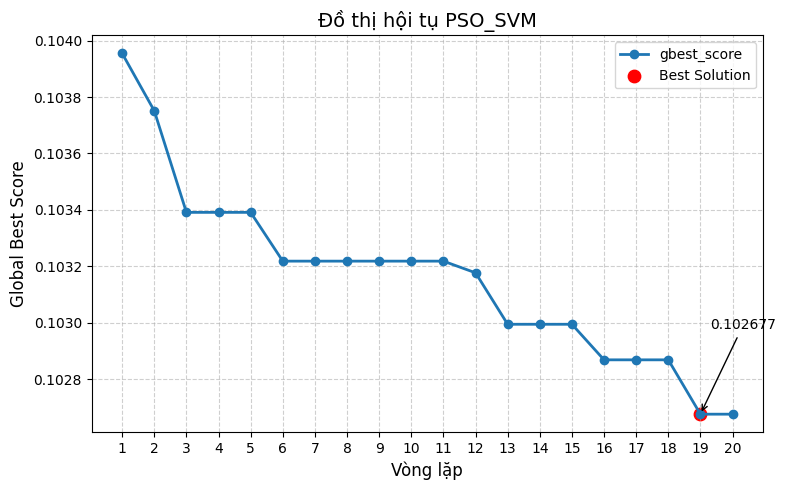

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.10395454745920994,
  0.10375098420673139,
  0.1033914514099785,
  0.1033914514099785,
  0.1033914514099785,
  0.1032187522344145,
  0.1032187522344145,
  0.1032187522344145,
  0.1032187522344145,
  0.1032187522344145,
  0.1032187522344145,
  0.10317738411797367,
  0.10299515149923834,
  0.10299515149923834,
  0.10299515149923834,
  0.10286923293390317,
  0.10286923293390317,
  0.10286923293390317,
  0.10267675749240557,
  0.10267675749240557
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ PSO_SVM", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

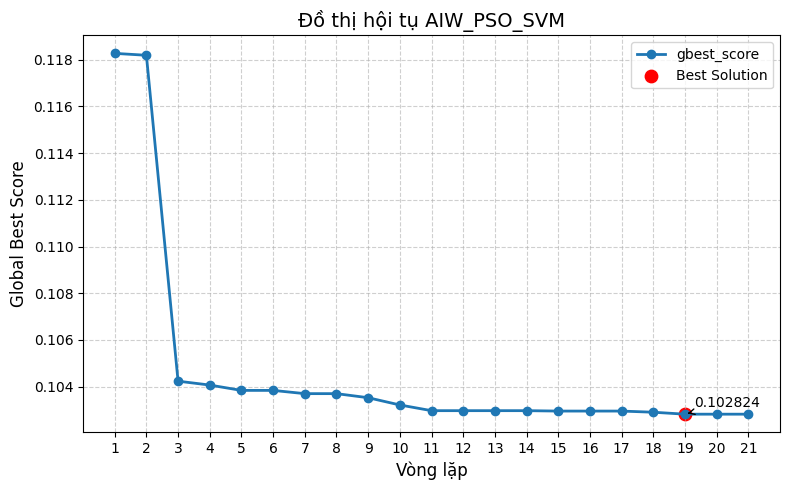

In [2]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.11826612752794602,
  0.11818468951875416,
  0.10423735340481903,
  0.10407094083917462,
  0.10384228075971684,
  0.10384228075971684,
  0.10370351746296384,
  0.10370351746296384,
  0.10352915318784338,
  0.10321894507431904,
  0.10297493372178586,
  0.10297493372178586,
  0.10297493372178586,
  0.10297493372178586,
  0.10295747181171745,
  0.10295747181171745,
  0.10295747181171745,
  0.10290833893787248,
  0.10282443000354131,
  0.10282443000354131,
  0.10282443000354131
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ AIW_PSO_SVM", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()